# INF201 – Deliverable 1
Værdata fra Meteorologisk institutt (Frost API) for Ås (SN17850).

**GitHub-repo:** LIM INN LENKE HER

In [1]:
import requests                  # sender forespørsler til Frost API
import pandas as pd              # tabeller (DataFrame) og statistikk
import matplotlib.pyplot as plt  # plotting

# Klient-ID-en leses fra en egen fil, så den ikke ligger i koden eller på GitHub
with open("frost_client_id.txt") as f:
    client_id = f.read().strip()

# Funksjonen til å hente data: 
Alle oppgavene henter data på samme måte, så hentingen er samlet i én funksjon.
Funksjonen er basert på Python-eksemplet fra MET (https://frost.met.no/python_example.html), men omskrevet og utvidet av oss.

Frost kan gi flere målinger for samme døgn med ulik `timeOffset` (hvilket klokkeslett døgnet regnes fra).
Vi beholder bare én per døgn: `PT0H` (midnatt til midnatt) hvis den finnes, ellers den første tilgjengelige.

**Merk om perioden:** I Frost er sluttdatoen i `referencetime` *ikke* med. `2025-01-01/2025-12-31` gir derfor
bare 364 dager. Vi bruker `2025-01-01/2026-01-01` for å få med 31. desember.

In [3]:
def hent_data(source, element, referencetime):
    """Henter daglige observasjoner fra Frost og returnerer en DataFrame med dato og verdi."""
    # Hvor vi spør, og hva vi spør om (stasjon, type måling og tidsperiode)
    endpoint = "https://frost.met.no/observations/v0.jsonld"
    parameters = {
        "sources": source,
        "elements": element,
        "referencetime": referencetime,
    }
    # Sender forespørselen. Klient-ID-en brukes som brukernavn, passordet er tomt
    r = requests.get(endpoint, parameters, auth=(client_id, ""))
    # Stopper med en tydelig feilmelding hvis Frost ikke svarer OK (200)
    if r.status_code != 200:
        raise RuntimeError(f"Feil {r.status_code}: {r.json()}")

    # JSON: hvert døgn har en liste med observasjoner.
    # Vi gjør det om til en rad per observasjon
    rows = []
    for obs in r.json()["data"]:
        for o in obs["observations"]:
            rows.append({
                "date": obs["referenceTime"],
                "value": o["value"],
                "timeOffset": o["timeOffset"],
            })
    df = pd.DataFrame(rows)

    # Én måling per døgn: bruk PT0H hvis den finnes, ellers første tilgjengelige
    offsets = df["timeOffset"].unique()
    valgt = "PT0H" if "PT0H" in offsets else offsets[0]
    df = df[df["timeOffset"] == valgt].copy()

    # Gjør tekst om til datoer, fjerner tidssone og klokkeslett så vi bare har selve dagen
    df["date"] = pd.to_datetime(df["date"]).dt.tz_localize(None).dt.normalize()
    return df[["date", "value"]].reset_index(drop=True)

# Oppgave 1: 
Tempraturer

In [4]:
# Henter døgnmiddeltemperatur for hele 2025 (sluttdatoen er ikke med, derfor 2026-01-01)
temp_2025 = hent_data("SN17850", "mean(air_temperature P1D)", "2025-01-01/2026-01-01")
print(len(temp_2025))  # sjekker at vi fikk 365 dager
temp_2025.head()

365


,date,value
0,2025-01-01,-5.2
1,2025-01-02,-11.5
2,2025-01-03,-8.9
3,2025-01-04,-15.5
4,2025-01-05,-12.5


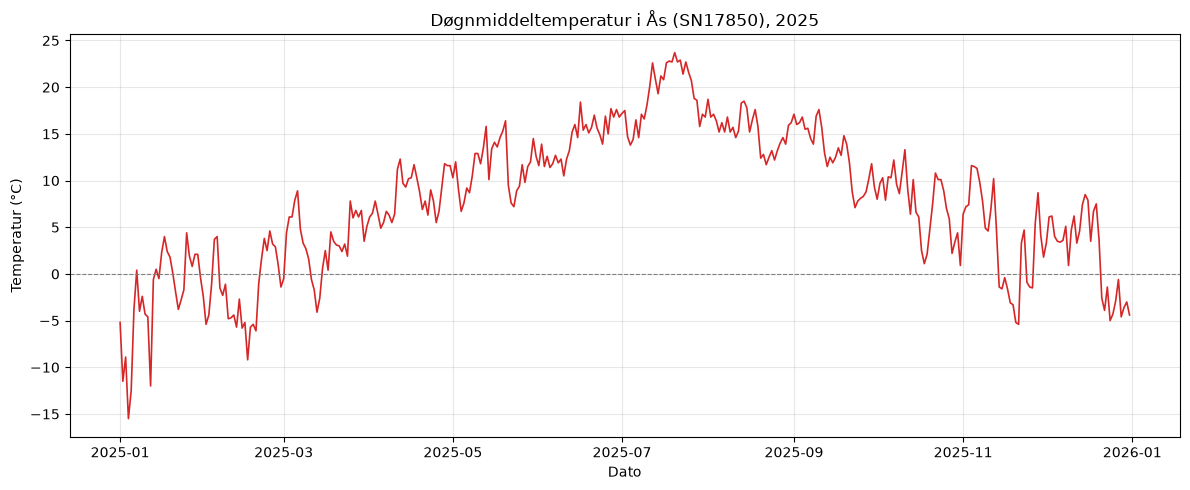

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(temp_2025["date"], temp_2025["value"], color="tab:red", linewidth=1.2)
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")  # stiplet linje ved 0 °C
ax.set_title("Døgnmiddeltemperatur i Ås (SN17850), 2025")
ax.set_xlabel("Dato")
ax.set_ylabel("Temperatur (°C)")
ax.grid(alpha=0.3)  # svakt rutenett gjør det lettere å lese av verdier
fig.tight_layout()
plt.show()

In [6]:
# Lager en liten tabell med navn på statistikken i én kolonne og verdien i en annen
summary = pd.DataFrame({
    "Statistikk": ["Gjennomsnitt", "Median", "Minimum", "Maksimum"],
    "Temperatur (°C)": [
        temp_2025["value"].mean(),
        temp_2025["value"].median(),
        temp_2025["value"].min(),
        temp_2025["value"].max(),
    ],
}).round(1)  # runder av til én desimal

# to_string(index=False) skjuler radnummerne så tabellen blir penere
print(summary.to_string(index=False))

  Statistikk  Temperatur (°C)
Gjennomsnitt              7.9
      Median              8.3
     Minimum            -15.5
    Maksimum             23.7


# DISKUSJON:
Plottet viser en tydelig sesongvariasjon: temperaturen er lavest om vinteren, stiger gjennom våren,
topper seg om sommeren og synker igjen mot slutten av året. Den stiplede linjen viser 0 °C, og man ser
at døgnmiddeltemperaturen ligger under frysepunktet i deler av vinteren.

Fra dag til dag svinger temperaturen ganske mye, særlig om vinteren. Det skyldes vær som skifter mellom
kalde, klare perioder og mildere perioder med skydekke og vind.

I tabellen er gjennomsnittet 7,9 °C og medianen 8,4 °C. De ligger nær hverandre, så fordelingen er nokså
symmetrisk gjennom året. At medianen er litt høyere enn gjennomsnittet, skyldes de få, svært kalde
vinterdagene som trekker gjennomsnittet ned. Laveste døgnmiddel var −15,5 °C, den 4. januar, helt i starten
av en kald periode i begynnelsen av januar. Høyeste døgnmiddel var 23,7 °C, i den varmeste perioden i
andre halvdel av juli.

# Oppgave 2
Nedbør

In [7]:
# Henter nedbør per døgn for samme periode som temperaturen
nedbor_2025 = hent_data("SN17850", "sum(precipitation_amount P1D)", "2025-01-01/2026-01-01")
print("Antall dager:", len(nedbor_2025))
print("Total nedbør 2025:", round(nedbor_2025["value"].sum(), 1), "mm")
print("Dager med nedbør (> 0 mm):", (nedbor_2025["value"] > 0).sum())  # True telles som 1
nedbor_2025.head()

Antall dager: 365
Total nedbør 2025: 942.2 mm
Dager med nedbør (> 0 mm): 184


,date,value
0,2025-01-01,5.4
1,2025-01-02,0.0
2,2025-01-03,0.1
3,2025-01-04,0.0
4,2025-01-05,0.5


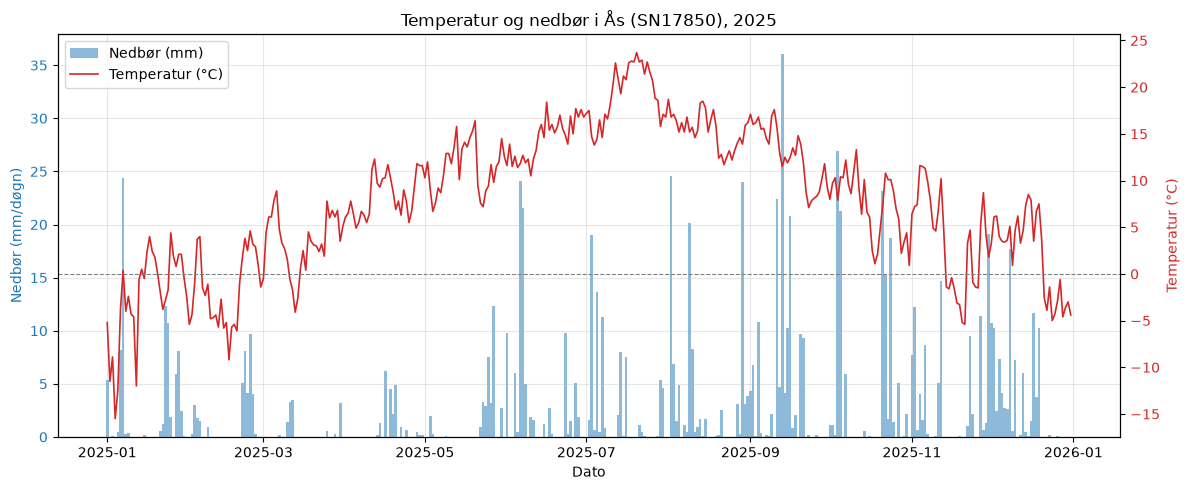

In [8]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Nedbør som søyler på venstre akse
ax1.bar(nedbor_2025["date"], nedbor_2025["value"], width=1.0,
        color="tab:blue", alpha=0.5, label="Nedbør (mm)")
ax1.set_xlabel("Dato")
ax1.set_ylabel("Nedbør (mm/døgn)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

# Temperatur som linje på høyre akse. twinx() lager en ny y-akse som deler x-aksen
ax2 = ax1.twinx()
ax2.plot(temp_2025["date"], temp_2025["value"],
         color="tab:red", linewidth=1.2, label="Temperatur (°C)")
ax2.axhline(0, color="grey", linewidth=0.8, linestyle="--")
ax2.set_ylabel("Temperatur (°C)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

# Felles forklaring for begge aksene
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")

ax1.set_title("Temperatur og nedbør i Ås (SN17850), 2025")
ax1.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Diskusjon
Vi valgte ulike plottyper for de to målingene:

- **Nedbør som søyler:** nedbør er en mengde som samles opp per døgn, og mange dager har 0 mm.
  En linje ville tegnet «overganger» mellom dager som ikke finnes, mens søyler viser hver dag for seg.
- **Temperatur som linje:** temperatur er en kontinuerlig størrelse som endrer seg gradvis, så en linje
  viser utviklingen best.
- **To y-akser:** målingene har ulike enheter og skalaer (mm og °C). Med én felles akse ville den ene
  blitt nesten flat. Aksene er farget likt med dataene, så det er tydelig hvilken akse som hører til hva.

Totalt kom det 942,2 mm nedbør i 2025, fordelt på 184 dager med nedbør, altså omtrent annenhver dag.
Plottet viser at nedbøren kommer i enkeltdager og perioder heller enn jevnt fordelt. Våren, fra mars til
mai, var svært tørr, med lite nedbør over lang tid. Fra juni ble det våtere, og høsten og forvinteren
(september–desember) hadde flest store nedbørsdøgn. Det største døgnet kom i september, med rundt 36 mm.

Vi ser ingen enkel sammenheng mellom temperatur og nedbørsmengde i plottet. Om vinteren ser det likevel ut
til at nedbøren ofte kommer i mildere perioder, når temperaturen ligger rundt eller over 0 °C.

# Oppgave 3
Historiske tempraturdata



In [9]:
# Samme stasjon og måling som i oppgave 1, men 100 år tidligere
temp_1925 = hent_data("SN17850", "mean(air_temperature P1D)", "1925-01-01/1926-01-01")
print("Antall dager 1925:", len(temp_1925))
temp_1925.head()

Antall dager 1925: 365


,date,value
0,1925-01-01,1.3
1,1925-01-02,4.1
2,1925-01-03,2.1
3,1925-01-04,0.1
4,1925-01-05,-2.2


For å plotte begge årene oppå hverandre flytter vi alle datoene til samme år (år 2000) og viser
**måned** på x-aksen. Ellers ville 1925 og 2025 havnet 100 år fra hverandre på aksen. Vi bruker år 2000
fordi det er et skuddår, så alle datoer (også en eventuell 29. februar) får plass.

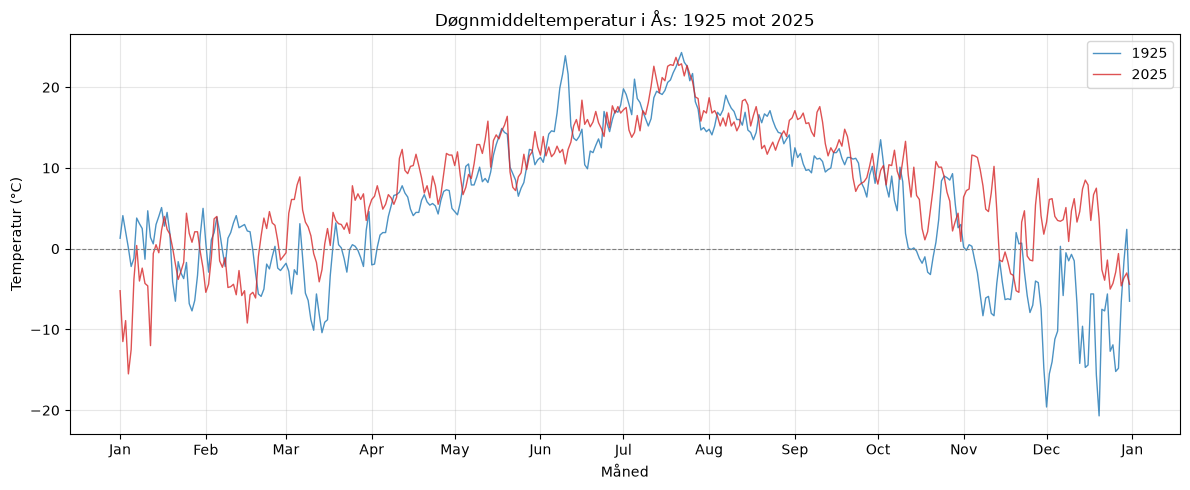

In [10]:
import matplotlib.dates as mdates  # for å vise måneder på x-aksen

def til_felles_aar(df):
    """Flytter alle datoer til år 2000, slik at ulike år kan plottes på samme x-akse."""
    return df["date"].apply(lambda d: d.replace(year=2000))

fig, ax = plt.subplots(figsize=(12, 5))
# Begge årene plottes på samme "år", så kurvene ligger oppå hverandre
ax.plot(til_felles_aar(temp_1925), temp_1925["value"],
        color="tab:blue", linewidth=1.0, alpha=0.8, label="1925")
ax.plot(til_felles_aar(temp_2025), temp_2025["value"],
        color="tab:red", linewidth=1.0, alpha=0.8, label="2025")
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")

# Ett merke per måned, vist som forkortet månedsnavn (Jan, Feb, ...)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title("Døgnmiddeltemperatur i Ås: 1925 mot 2025")
ax.set_xlabel("Måned")
ax.set_ylabel("Temperatur (°C)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [11]:
def oppsummering(serier):
    """Lager en tabell med gjennomsnitt, median, min og maks for én eller flere tidsserier."""
    # Én kolonne per serie (f.eks. per år), én rad per statistikk
    tabell = pd.DataFrame({
        navn: [s.mean(), s.median(), s.min(), s.max()]
        for navn, s in serier.items()
    }, index=["Gjennomsnitt", "Median", "Minimum", "Maksimum"])
    return tabell.round(1)


tabell_sammenligning = oppsummering({
    "1925 (°C)": temp_1925["value"],
    "2025 (°C)": temp_2025["value"],
})
# Ekstra kolonne som viser hvor mye varmere (+) eller kaldere (-) 2025 var
tabell_sammenligning["Differanse (°C)"] = (
    tabell_sammenligning["2025 (°C)"] - tabell_sammenligning["1925 (°C)"]
).round(1)
print(tabell_sammenligning.to_string())

              1925 (°C)  2025 (°C)  Differanse (°C)
Gjennomsnitt        5.3        7.9              2.6
Median              5.3        8.3              3.0
Minimum           -20.7      -15.5              5.2
Maksimum           24.3       23.7             -0.6


### Diskusjon
Begge årene har samme sesongmønster med kalde vintre og varme somre, men tabellen viser forskjellene.
Gjennomsnittet i 2025 var 7,9 °C mot 5,3 °C i 1925, altså en forskjell på 2,6 °C. Medianen var 3,1 °C høyere.

Det mest interessante er at forskjellen ligger i den kalde delen av året. Laveste døgnmiddel var 5,2 °C
høyere i 2025 (−15,5 °C mot −20,7 °C), mens høyeste døgnmiddel faktisk var litt lavere (23,7 °C mot 24,3 °C).
Plottet viser det samme: somrene ligger nokså likt, mens november og desember var mye kaldere i 1925, med
flere dager ned mot −20 °C. Mars og april var også varmere i 2025. Unntaket er starten av januar, der 2025
hadde en kald periode som 1925 ikke hadde.

Det er viktig å være forsiktig med konklusjonene:
- **Ett år er ikke klima.** Temperaturen varierer mye fra år til år, så to enkeltår kan ikke alene vise
  en klimatrend. For det trengs gjennomsnitt over mange år, typisk 30-årsperioder.
- **Målingene er ikke nødvendigvis like.** Instrumenter, plassering og hvordan døgnmiddelet beregnes kan
  ha endret seg på 100 år. Omgivelsene rundt stasjonen kan også ha endret seg.

Samtidig stemmer en eventuell høyere temperatur i 2025 med den kjente oppvarmingen i Norge det siste århundret.

# Oppgave 4 Hetebølger

I Norge er en hetebølge definert som **minst fem sammenhengende dager** der **maksimumstemperaturen er
minst 27 °C**. Vi bruker derfor `max(air_temperature P1D)`, ikke døgnmiddelet.

Funksjonen `tell_hetebolger`:
1. tar inn stasjons-ID (f.eks. `"SN17850"`), stasjonsnavn (f.eks. `"Ås"`) og et år,
2. henter maksimumstemperaturen for hele året,
3. finner alle perioder med sammenhengende dager ≥ 27 °C,
4. teller perioder som er minst 5 dager lange,
5. skriver en oppsummering til en `.yml`-fil og returnerer antallet.

Dager som mangler i dataene bryter en periode, siden vi ikke vet om de var over 27 °C.

In [12]:
import yaml  # for å skrive yml-filen

def tell_hetebolger(station_id, station_name, year, grense=27.0, min_dager=5):
    """Teller hetebølger for en stasjon og et år, og skriver en oppsummering til en yml-fil."""
    # Henter maksimumstemperatur (ikke middel) for hele året
    maks = hent_data(station_id, "max(air_temperature P1D)", f"{year}-01-01/{year + 1}-01-01")

    perioder = []    # ferdige hetebølger som (start, slutt)
    gjeldende = []   # datoene i perioden vi holder på med nå

    # Går gjennom dagene én etter én
    for dato, temp in zip(maks["date"], maks["value"]):
        varm = temp >= grense
        # Perioden fortsetter bare hvis dagen kommer rett etter forrige varme dag i kalenderen
        fortsetter = gjeldende and (dato - gjeldende[-1]).days == 1

        if varm and fortsetter:
            gjeldende.append(dato)              # perioden fortsetter
        else:
            if len(gjeldende) >= min_dager:     # forrige periode var lang nok
                perioder.append((gjeldende[0], gjeldende[-1]))
            gjeldende = [dato] if varm else []  # start ny periode eller nullstill

    if len(gjeldende) >= min_dager:             # sjekk perioden som pågår ved årets slutt
        perioder.append((gjeldende[0], gjeldende[-1]))

    # Skriv oppsummering i samme format som eksempelfilen
    summary = {
        "station_id": station_id,
        "station_name": station_name,
        "year": year,
        "dates": [f"{s:%Y-%m-%d} - {e:%Y-%m-%d}" for s, e in perioder],
    }
    # Filnavnet inneholder stasjon og år, så kjøringer for ulike år ikke overskriver hverandre
    filnavn = f"heatwave_summary_{station_id}_{year}.yml"
    with open(filnavn, "w") as f:
        yaml.dump(summary, f)

    print(f"Skrev oppsummering til {filnavn}")
    return len(perioder)

In [13]:
antall = tell_hetebolger("SN17850", "Ås", 2025)
print("Antall hetebølger i Ås i 2025:", antall)
print()
# Skriver ut innholdet i yml-filen for å vise at formatet er riktig
print(open("heatwave_summary_SN17850_2025.yml").read())

Skrev oppsummering til heatwave_summary_SN17850_2025.yml
Antall hetebølger i Ås i 2025: 1

dates:
- 2025-07-16 - 2025-07-20
station_id: SN17850
station_name: "\xC5s"
year: 2025



Funksjonen fungerer for hvilken som helst stasjon og hvilket som helst år. Her kjører vi den for 2018,
som var en kjent varm sommer:

In [14]:
tell_hetebolger("SN17850", "Ås", 2018)

Skrev oppsummering til heatwave_summary_SN17850_2018.yml


1

### Diskusjon
Funksjonen fant en hetebølge i Ås i 2025, fra 16. til 20. juli. Den varte nøyaktig fem dager, altså akkurat
det som kreves for å regnes som hetebølge. Hadde en av dagene vært under 27 °C, ville det ikke blitt registrert
noen hetebølge i det hele tatt. Det viser hvor følsomt resultatet er for en fast grense. Perioden faller sammen
med den varmeste delen av året i plottet fra oppgave 1. For 2018 fant funksjonen også en hetebølge.

Noen valg vi tok i implementeringen:
- Vi sjekker at dagene faktisk er **sammenhengende i kalenderen**, ikke bare etter hverandre i tabellen.
  Mangler en dag i dataene, brytes perioden, fordi vi ikke kan vite om den dagen var varm nok.
- Grensen (27 °C) og minstelengden (5 dager) er parametere med standardverdier, så funksjonen kan brukes
  med andre definisjoner også.
- Stasjons-ID og stasjonsnavn gis som egne argumenter. ID-en brukes til å hente data, og navnet skrives
  til yml-filen. Filen får samme format som eksempelfilen fra kurset.

## Oppgave 5: Glidende gjennomsnitt
Et 7-dagers glidende gjennomsnitt jevner ut svingningene fra dag til dag, slik at den underliggende
trenden blir tydeligere. Vi bruker et **sentrert** vindu: verdien for en dag er snittet av dagen selv,
de tre dagene før og de tre dagene etter.

In [15]:
def glidende_gjennomsnitt(verdier, vindu=7):
    """Beregner sentrert glidende gjennomsnitt.

    De første og siste dagene får NaN, fordi det ikke finnes nok dager på begge sider til et fullt vindu.
    """
    # rolling() lager et "vindu" som flyttes én dag om gangen, og mean() tar snittet i hvert vindu.
    # center=True betyr at dagen står i midten av vinduet (3 dager før og 3 etter)
    return verdier.rolling(window=vindu, center=True).mean()


# Legger det glidende gjennomsnittet til som en ny kolonne i tabellen
temp_2025["glidende_7d"] = glidende_gjennomsnitt(temp_2025["value"], vindu=7)
temp_2025.head(10)

,date,value,glidende_7d
0,2025-01-01,-5.2,NaN
1,2025-01-02,-11.5,NaN
2,2025-01-03,-8.9,NaN
3,2025-01-04,-15.5,-8.142857
4,2025-01-05,-12.5,-7.971429
5,2025-01-06,-3.8,-6.671429
6,2025-01-07,0.4,-6.014286
7,2025-01-08,-4.0,-4.457143
8,2025-01-09,-2.4,-4.385714
9,2025-01-10,-4.3,-3.928571


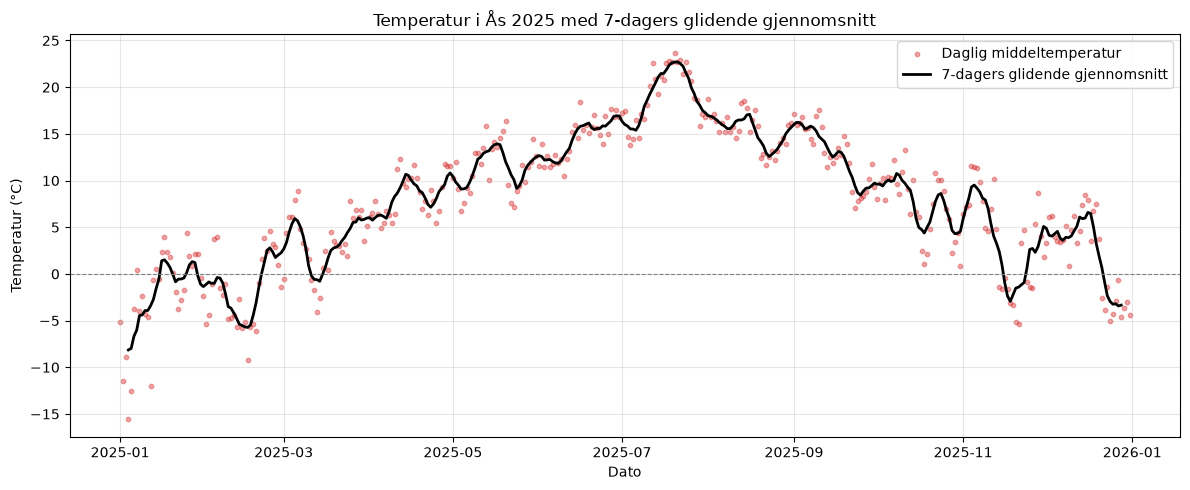

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))
# Daglige verdier som små, litt gjennomsiktige punkter
ax.scatter(temp_2025["date"], temp_2025["value"],
           s=10, color="tab:red", alpha=0.4, label="Daglig middeltemperatur")
# Glidende gjennomsnitt som en tydelig linje oppå
ax.plot(temp_2025["date"], temp_2025["glidende_7d"],
        color="black", linewidth=2, label="7-dagers glidende gjennomsnitt")
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")
ax.set_title("Temperatur i Ås 2025 med 7-dagers glidende gjennomsnitt")
ax.set_xlabel("Dato")
ax.set_ylabel("Temperatur (°C)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Diskusjon
Punktene viser hvor mye temperaturen hopper fra dag til dag, mens det glidende gjennomsnittet viser
den jevnere utviklingen. Det gjør det lettere å se sesongvariasjonen og lengre varme- og kuldeperioder.

Valg og begrensninger:
- **Sentrert vindu** gjør at kurven ikke blir forskjøvet i tid. Et bakoverskuende vindu (bare de 7
  siste dagene) ville fått kurven til å «henge etter» de faktiske endringene.
- De **tre første og tre siste dagene** mangler verdi, fordi det ikke finnes nok data på begge sider.
- **Vindusstørrelsen** er en avveining: et større vindu gir glattere kurve, men visker også ut korte,
  ekte svingninger.

## Bruk av generativ KI
Vi har brukt KI (Claude) til å forstå oppgaven til å begynne og hjelp med å bygge opp koden. 

**Underveis i oppgaven:**
Vi brukte Claude i studiemodus mens vi løste oppgavene.
Målet var å lære, ikke bare å få ferdig kode. Claude hjalp oss med å bygge opp koden steg for steg og forklarte hva de ulike delene gjør, for eksempel hvordan man henter data fra Frost API, hvordan svaret gjøres om til en pandas-tabell, og hvordan man lager plott med matplotlib. Vi skrev og kjørte koden selv og stilte oppfølgingsspørsmål når noe var uklart.

**Før innlevering:**
Claude til å kontrollere den ferdige notatboka mot
oppgaveteksten. Claude:
- fant at oppgave 1 hentet 364 i stedet for 365 dager, fordi sluttdatoen i Frost ikke er med,
- pekte på steder der markdown-teksten ikke stemte med koden (beskrivelsen av x-aksen i oppgave 3 og stasjonsoppslag i oppgave 4),
- minnet oss på det som manglet: GitHub-lenke, referanser og denne seksjonen,
- skrev utkast til diskusjonene ut fra tallene og plottene våre,
- la til korte kommentarer i koden, slik at det er lettere å huske og forklare hva den gjør,
- hjalp oss med praktiske problemer: en feil med matplotlib (pakken var ikke installert i miljøet vi kjørte i), oppsett av klient-ID fra frost.met.no i en egen fil som ikke legges på GitHub, og hvordan man kjører notatboka i VS Code
**Hvordan vi har kontrollert det.**
Vi har kjørt hele notatboka på nytt og sjekket at tallene i diskusjonene stemmer med output fra koden. Diskusjonene har vi lest gjennom og tilpasset. Claude har ikke tilgang til Frost, så alle data og resultater kommer fra vår egen kjøring.

**Refleksjon.** 
Studiemodus var nyttig for å forstå koden, ikke bare kopiere den. Gjennomgangen fanget opp feil
vi selv hadde oversett, særlig periodefeilen og tekst som ikke lenger stemte med koden. Samtidig så vi at KI kan ta feil, så vi har kontrollert det den foreslo mot oppgaveteksten og mot resultatene våre.

## Referanser
- Meteorologisk institutt (MET Norway). Værdata hentet fra Frost API, https://frost.met.no. Data er lisensiert under CC BY 4.0.
- MET Norway. *Python example*, https://frost.met.no/python_example.html (grunnlag for funksjonen `hent_data`).
- Meteorologisk institutt. Artikkel om hetebølger og definisjonen som brukes i Norge (lenket i oppgaveteksten).